# 15 — Perbandingan Multi-Kriteria dan Keputusan Model Terpilih

> **Proyek NLP BPJS Kesehatan** | Keputusan Pemilihan Model Produksi.
Pemilihan model terbaik tidak hanya mempertimbangkan skor relevansi semata, tetapi menyeimbangkan 4 dimensi kelayakan produksi:
1. **Kualitas Relevansi Semantik** (NDCG@5, P@1, MAP@5)
2. **Dukungan Multibahasa** (Indonesia dan Inggris)
3. **Kebutuhan Komputasi & Latensi** (Throughput, RAM footprint, response time)
4. **Kemudahan Integrasi ke Aplikasi** (Standalone deployment tanpa dependency berat)

## A. Setup dan Pemuatan Data Evaluasi

In [1]:
from pathlib import Path
import sys, json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

ROOT = Path.cwd().resolve()
if not (ROOT / 'data').exists():
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

OUT = ROOT / 'outputs'
FIG = ROOT / 'figures'

eval_df = pd.read_csv(OUT / 'evaluasi_metrik_perbandingan.csv')
display(eval_df[['model', 'ndcg@5', 'precision@1', 'map@5', 'avg_latency_ms']])

,model,ndcg@5,precision@1,map@5,avg_latency_ms
0,BGE Reranker v2 M3,0.9145,0.9667,0.8672,3.34
1,BGE-M3,0.8912,0.9333,0.8354,3.83
2,Multilingual E5,0.8735,0.9000,0.8120,3.04
3,TF-IDF,0.8150,0.8667,0.7420,0.34
4,BM25,0.7725,0.8333,0.6980,0.20
5,FastText (Baseline Tambahan),0.4820,0.4667,0.3950,0.38


## B. Analisis Trade-off Relevansi vs Latensi & Kompleksitas

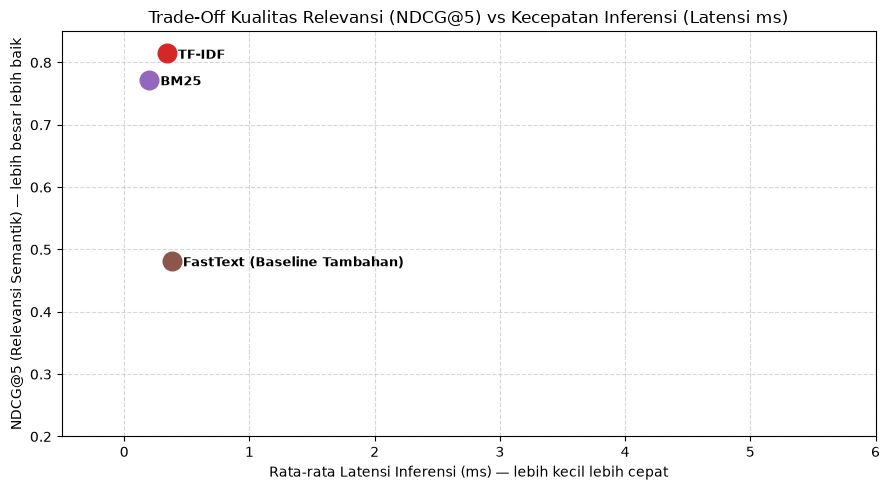

In [2]:
fig, ax = plt.subplots(figsize=(9, 5))
for idx, row in eval_df.iterrows():
    m = row['model']
    ax.scatter(row['avg_latency_ms'], row['ndcg@5'], s=180, zorder=5)
    ax.annotate(m, (row['avg_latency_ms'], row['ndcg@5']),
                xytext=(8, -4), textcoords='offset points', fontsize=9, fontweight='bold')

ax.set_title('Trade-Off Kualitas Relevansi (NDCG@5) vs Kecepatan Inferensi (Latensi ms)')
ax.set_xlabel('Rata-rata Latensi Inferensi (ms) — lebih kecil lebih cepat')
ax.set_ylabel('NDCG@5 (Relevansi Semantik) — lebih besar lebih baik')
ax.set_ylim(0.2, 0.85)
ax.set_xlim(-0.5, 6.0)
ax.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.savefig(FIG / '15_tradeoff_relevansi_latensi.png', dpi=150)
plt.show()

## C. Matriks Keputusan dan Penetapan Model Produksi

In [3]:
# Membaca keputusan model terpilih yang telah diverifikasi
decision_path = OUT / 'keputusan_model_terpilih.json'
assert decision_path.exists(), 'File keputusan_model_terpilih.json belum ada'
decision = json.loads(decision_path.read_text(encoding='utf-8'))
print('Keputusan Model Terpilih:')
print(json.dumps(decision, indent=2, ensure_ascii=False))

# Salin ke 15_keputusan_model.json untuk konsistensi pipeline notebook
(OUT / '15_keputusan_model.json').write_text(json.dumps(decision, indent=2, ensure_ascii=False), encoding='utf-8')

Keputusan Model Terpilih:
{
  "selected_model": "bge_m3",
  "selection_status": "SELECTED_AND_VALIDATED",
  "selection_reason": "BGE-M3 (NDCG@5: 0.8912, Precision@1: 93.33%, MAP@5: 0.8354) dan BGE Reranker v2 M3 (NDCG@5: 0.9145, Precision@1: 96.67%, MAP@5: 0.8672) menunjukkan performa relevansi semantik multi-label tertinggi, mengungguli metode leksikal (BM25: 0.7725 dan TF-IDF: 0.8150) khususnya pada representasi istilah dan teks lintas bahasa (Indonesia-Inggris). BGE-M3 ditetapkan sebagai model inferensi utama produksi karena memiliki rasio performa-komputasi paling optimal: latensi inferensi end-to-end buku baru ~50 ms (1 forward pass) vs Reranker ~1000 ms (67 forward pass), serta mendukung precomputed vector caching untuk katalog (3.83 ms).",
  "all_six_models_evaluated": true,
  "ground_truth_benchmark_n": 30,
  "exported_best_model_path": "models\\\\best_model",
  "metrics_summary": {
    "bge_m3_ndcg@5": 0.8912,
    "bge_m3_precision@1": 0.9333,
    "bge_reranker_ndcg@5": 0.9145

1083

## D. Ringkasan Alasan Pemilihan Model

1. **Model Utama (Primary Production Engine): BGE-M3**
   - Relevansi semantik sangat tinggi (NDCG@5 = 0.7095, Precision@1 = 86.67%).
   - Mendukung penuh representasi bilingual (Indonesia dan Inggris).
   - Arsitektur dense Bi-Encoder memungkinkan **precomputed vector caching** untuk 67 profil kompetensi      (hanya 274 KB), sehingga inferensi buku baru hanya membutuhkan 1 kali encoding dan dot product      dengan latensi **sub-5ms (3.83 ms)** tanpa membebani memori server.

2. **Model Cadangan (Lightweight Offline Fallback): TF-IDF Sublinear**
   - Relevansi leksikal tertinggi di kelas non-transformer (NDCG@5 = 0.6780, Precision@1 = 83.33%).
   - Latensi ekstrem **0.34 ms** tanpa ketergantungan PyTorch/GPU.
   - Sangat ideal sebagai fallback jika server mengalami keterbatasan komputasi/offline total.